In [7]:
# Imports and Paths

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.metrics import r2_score
from sklearn.model_selection import GroupKFold, RepeatedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set(style="whitegrid")

project_root = Path.cwd().parent
data_dir = project_root / "data"
raw_dir = data_dir / "raw"
processed_dir = data_dir / "processed"
figures_dir = project_root / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

MODEL_COL, DRUG_COL, RESPONSE_COL = "model_id", "drug_name", "ln_ic50"
TISSUE_COL = "tissue"
MIN_TISSUE_N = 10 # Tissues with fewer cell lines are pooled into "Other"
ALPHAS = np.logspace(-2, 5, 15)
SEED = 42
RUN_RF = True

In [8]:
# Load data and attach tissue to each cell line

df = pd.read_csv(processed_dir / "cisplatin_rnaseq_modelready_clean.csv")
ann = pd.read_csv(raw_dir / "models.csv", usecols=[MODEL_COL, TISSUE_COL])

n_before = len(df)
df = df.merge(ann, on=MODEL_COL, how="left")
assert len(df) == n_before, "merge changed the number of rows (duplicate model_ids in annotation?)"
df[TISSUE_COL] = df[TISSUE_COL].fillna("Unknown") # Labels cell lines with no tissue

counts = df[TISSUE_COL].value_counts()
small = counts[counts < MIN_TISSUE_N].index
df["tissue_group"] = df[TISSUE_COL].where(~df[TISSUE_COL].isin(small), "Other") # Tissues in the small list go into "Other"

gene_cols = [c for c in df.columns
             if c not in {MODEL_COL, DRUG_COL, RESPONSE_COL, TISSUE_COL, "tissue_group"}]
y = df[RESPONSE_COL].to_numpy()
X_expr = df[gene_cols].to_numpy()
X_tissue = df[["tissue_group"]]
X_both = pd.concat([df[["tissue_group"]], df[gene_cols]], axis=1)

print(f"{len(df)} cell lines, {len(gene_cols)} genes, {df['tissue_group'].nunique()} tissue groups")
df["tissue_group"].value_counts()

C:\Users\draar\AppData\Local\Temp\ipykernel_10348\2903361623.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["tissue_group"] = df[TISSUE_COL].where(~df[TISSUE_COL].isin(small), "Other") # Tissues in the small list go into "Other"


743 cell lines, 36438 genes, 21 tissue groups


tissue_group
Haematopoietic and Lymphoid    132
Lung                           127
Breast                          51
Large Intestine                 43
Central Nervous System          39
Bone                            35
Skin                            31
Ovary                           31
Pancreas                        30
Esophagus                       30
Head and Neck                   27
Stomach                         24
Peripheral Nervous System       23
Other                           18
Bladder                         17
Kidney                          17
Soft Tissue                     16
Thyroid                         14
Liver                           14
Cervix                          13
Endometrium                     11
Name: count, dtype: int64

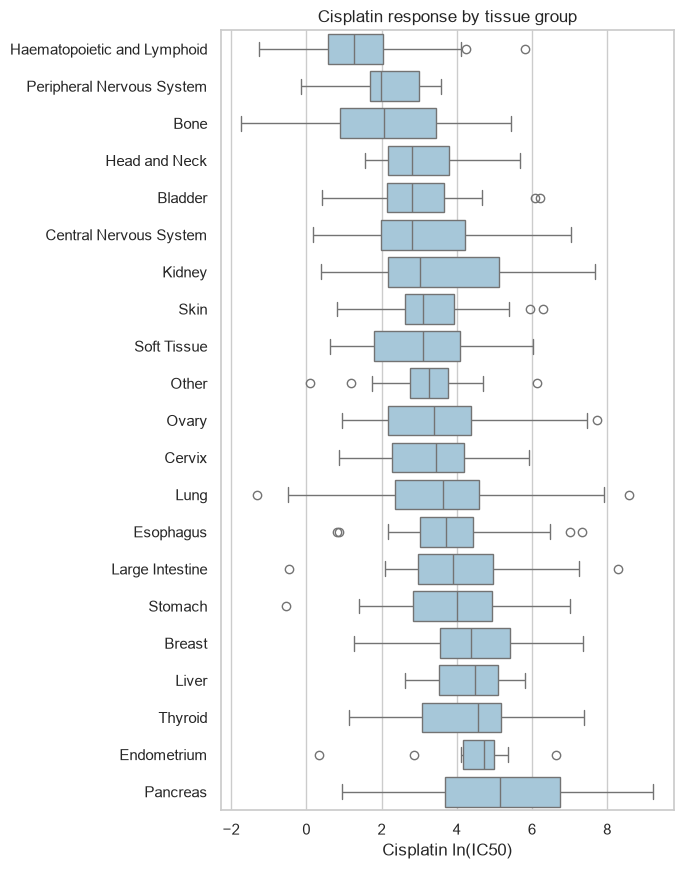

In [9]:
# Response by tissue group (is model scoring well just by recognizing tissue?)

order = df.groupby("tissue_group")[RESPONSE_COL].median().sort_values().index
fig, ax = plt.subplots(figsize=(7, 0.35 * len(order) + 1.5))
sns.boxplot(data=df, y="tissue_group", x=RESPONSE_COL, order=order, ax=ax, color="#9ecae1")
ax.set_xlabel("Cisplatin ln(IC50)")
ax.set_ylabel("")
ax.set_title("Cisplatin response by tissue group")
plt.tight_layout()
plt.savefig(figures_dir / "response_by_tissue.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
# Models and cross validation

def expression_ridge():
    return make_pipeline(SimpleImputer(strategy="mean"), StandardScaler(), RidgeCV(alphas=ALPHAS)) # Ridge picks best alpha on its own

def expression_rf():
    return make_pipeline(
        SimpleImputer(strategy="mean"),
        RandomForestRegressor(n_estimators=300, max_depth=7, max_features=200,
                              min_samples_leaf=5, n_jobs=-1, random_state=SEED))

# Predicts response using only tissue, not gene expression
def tissue_only():
    return make_pipeline(
        ColumnTransformer([("t", OneHotEncoder(handle_unknown="ignore"), ["tissue_group"])]),
        Ridge(alpha=1.0))

class TissueThenExpression(BaseEstimator, RegressorMixin):

    # Compute average response grouped by tissue type, then trains Ridge on residuals
    def fit(self, X, y):
        tissue = X["tissue_group"].to_numpy()
        self.global_mean_ = float(np.mean(y)) # Overall average repsonse, for tissues unknwon to the model
        self.tissue_means_ = pd.Series(y).groupby(tissue).mean().to_dict()
        resid = y - np.array([self.tissue_means_[t] for t in tissue]) # What can't be explained by tissue
        self.expr_ = expression_ridge().fit(X.drop(columns="tissue_group").to_numpy(), resid)
        return self

    # Combine average response by tissue (or overall average) with associated Ridge prediction
    def predict(self, X):
        tissue = X["tissue_group"].to_numpy()
        base = np.array([self.tissue_means_.get(t, self.global_mean_) for t in tissue])
        return base + self.expr_.predict(X.drop(columns="tissue_group").to_numpy())

def expression_plus_tissue():
    return TissueThenExpression()

# Simplify indexing so it works the same for both numpy arrays and pandas tables
def take(X, idx):
    return X.iloc[idx] if hasattr(X, "iloc") else X[idx]

# Takes one model then trains and tests it on every split
def evaluate(name, make_model, X, splits, folds_per_repeat):
    fold_r2, oof_list = [], []
    for i, (tr, te) in enumerate(splits):
        if i % folds_per_repeat == 0:
            oof = np.full(len(y), np.nan)
        m = make_model().fit(take(X, tr), y[tr])
        pred = m.predict(take(X, te))
        fold_r2.append(r2_score(y[te], pred))
        oof[te] = pred # After all 5 folds in one pass, holds one prediction for each cell line
        if i % folds_per_repeat == folds_per_repeat - 1:
            oof_list.append(r2_score(y, oof))
    return {"model": name, "pooled_r2": np.mean(oof_list),
            "mean_fold_r2": np.mean(fold_r2), "sd_fold_r2": np.std(fold_r2),
            "n_folds": len(fold_r2)}

random_splits = list(RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED).split(X_expr)) # Rows split into 5 parts, 3 different times with different shuffles each time = 15 splits
n_group_folds = min(5, df["tissue_group"].nunique())
group_splits = list(GroupKFold(n_splits=n_group_folds)
                    .split(X_expr, y, groups=df["tissue_group"]))

In [11]:
# Run everything

rows = []
for cv_name, splits, fpr in [("Random 5-fold x3", random_splits, 5),
                             ("Leave-tissue-out", group_splits, n_group_folds)]:
    jobs = [("Mean baseline", lambda: DummyRegressor(), X_tissue),
            ("Tissue only", tissue_only, X_tissue),
            ("Expression Ridge", expression_ridge, X_expr),
            ("Expression + tissue Ridge", expression_plus_tissue, X_both)]
    if RUN_RF:
        jobs.append(("Expression RF", expression_rf, X_expr))
    for name, mk, X in jobs:
        r = evaluate(name, mk, X, splits, fpr)
        r["cv"] = cv_name
        rows.append(r)
        print(f"{cv_name:18s} {name:27s} pooled R2 = {r['pooled_r2']:.3f}  "
              f"(fold mean {r['mean_fold_r2']:.3f} +/- {r['sd_fold_r2']:.3f})")

cv_results = pd.DataFrame(rows)[["cv", "model", "pooled_r2", "mean_fold_r2", "sd_fold_r2", "n_folds"]]
cv_results.to_csv(data_dir / "metadata" / "cv_results.csv", index=False)
cv_results

Random 5-fold x3   Mean baseline               pooled R2 = -0.002  (fold mean -0.005 +/- 0.006)
Random 5-fold x3   Tissue only                 pooled R2 = 0.274  (fold mean 0.271 +/- 0.051)
Random 5-fold x3   Expression Ridge            pooled R2 = 0.414  (fold mean 0.411 +/- 0.064)
Random 5-fold x3   Expression + tissue Ridge   pooled R2 = 0.388  (fold mean 0.383 +/- 0.080)
Random 5-fold x3   Expression RF               pooled R2 = 0.356  (fold mean 0.354 +/- 0.037)
Leave-tissue-out   Mean baseline               pooled R2 = -0.113  (fold mean -0.476 +/- 0.646)
Leave-tissue-out   Tissue only                 pooled R2 = -0.064  (fold mean -0.414 +/- 0.637)
Leave-tissue-out   Expression Ridge            pooled R2 = 0.190  (fold mean -0.087 +/- 0.538)
Leave-tissue-out   Expression + tissue Ridge   pooled R2 = 0.150  (fold mean -0.105 +/- 0.360)
Leave-tissue-out   Expression RF               pooled R2 = 0.138  (fold mean -0.142 +/- 0.465)


,cv,model,pooled_r2,mean_fold_r2,sd_fold_r2,n_folds
0,Random 5-fold x3,Mean baseline,-0.001910,-0.005440,0.006474,15
1,Random 5-fold x3,Tissue only,0.274154,0.270818,0.051176,15
2,Random 5-fold x3,Expression Ridge,0.413885,0.410839,0.064260,15
3,Random 5-fold x3,Expression + tissue Ridge,0.388016,0.383451,0.080305,15
4,Random 5-fold x3,Expression RF,0.355602,0.353759,0.037141,15
5,Leave-tissue-out,Mean baseline,-0.112573,-0.475726,0.645724,5
6,Leave-tissue-out,Tissue only,-0.063961,-0.413571,0.636900,5
7,Leave-tissue-out,Expression Ridge,0.189908,-0.086990,0.538072,5
8,Leave-tissue-out,Expression + tissue Ridge,0.149817,-0.105135,0.360008,5
9,Leave-tissue-out,Expression RF,0.138439,-0.141917,0.464813,5


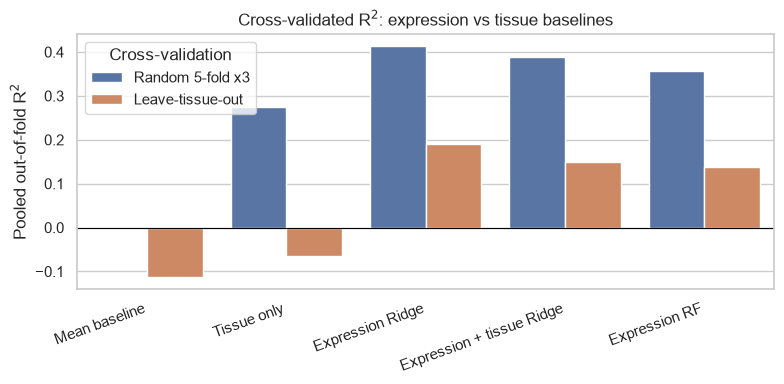

In [12]:
plot_df = cv_results.copy()
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=plot_df, x="model", y="pooled_r2", hue="cv", ax=ax)
ax.legend(title="Cross-validation", loc="upper left")
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Pooled out-of-fold R$^2$")
ax.set_xlabel("")
ax.set_title("Cross-validated R$^2$: expression vs tissue baselines")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(figures_dir / "cv_r2_comparison.png", dpi=300, bbox_inches="tight")
plt.show()